In [1]:
import os, time, json, random, copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms, datasets
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score
from PIL import Image
import matplotlib.pyplot as plt

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
set_seed()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 32
MAX_EPOCHS = 30
PATIENCE = 4          # protokol: 3 s.d. 5
WEIGHT_DECAY = 1e-2
NUM_CLASSES = 10
OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)
print("Device:", DEVICE, "| torch", torch.__version__)

Device: cuda | torch 2.11.0+cu128


## 1. Data: subset 10 kelas + split stratified 70/15/15
Di Oxford-IIIT Pet, nama kelas kucing diawali huruf kapital dan anjing huruf kecil.
Subset dipilih deterministik (5 kucing + 5 anjing pertama). Dua split bawaan (trainval + test) 

In [2]:
root = "./data"
tv = datasets.OxfordIIITPet(root=root, split="trainval", target_types="category", download=True)
te = datasets.OxfordIIITPet(root=root, split="test", target_types="category", download=True)

all_paths = [str(p) for p in list(tv._images) + list(te._images)]
all_labels = list(tv._labels) + list(te._labels)
classes = tv.classes

cat_ids = [i for i, c in enumerate(classes) if c[0].isupper()]
dog_ids = [i for i, c in enumerate(classes) if c[0].islower()]
selected = cat_ids[:5] + dog_ids[:5]
label_map = {orig: new for new, orig in enumerate(selected)}
class_names = [classes[i] for i in selected]
print("Kelas terpilih:", class_names)

paths = [p for p, l in zip(all_paths, all_labels) if l in label_map]
labels = [label_map[l] for l in all_labels if l in label_map]
print("Total citra subset:", len(paths))

idx = np.arange(len(paths))
idx_train, idx_tmp = train_test_split(idx, test_size=0.30, stratify=labels, random_state=SEED)
tmp_labels = [labels[i] for i in idx_tmp]
idx_val, idx_test = train_test_split(idx_tmp, test_size=0.50, stratify=tmp_labels, random_state=SEED)

def subset(ix): return [paths[i] for i in ix], [labels[i] for i in ix]
train_p, train_y = subset(idx_train)
val_p, val_y = subset(idx_val)
test_p, test_y = subset(idx_test)
print(f"train={len(train_p)}  val={len(val_p)}  test={len(test_p)}")

100%|██████████| 792M/792M [00:36<00:00, 21.5MB/s]  
100%|██████████| 19.2M/19.2M [00:02<00:00, 8.60MB/s]


Kelas terpilih: ['Abyssinian', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle']
Total citra subset: 998
train=698  val=150  test=150


## 2. Transformasi dan DataLoader


In [3]:
weights = models.ResNet18_Weights.IMAGENET1K_V1
eval_tf = weights.transforms()                 # Resize(256) -> CenterCrop(224) -> Normalize
MEAN, STD = eval_tf.mean, eval_tf.std

train_tf_aug = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])
train_tf_plain = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

class PetSubset(Dataset):
    def __init__(self, paths, labels, tf):
        self.paths, self.labels, self.tf = paths, labels, tf
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return self.tf(img), self.labels[i]

def make_loaders(use_aug):
    g = torch.Generator().manual_seed(SEED)
    tr = PetSubset(train_p, train_y, train_tf_aug if use_aug else train_tf_plain)
    va = PetSubset(val_p, val_y, eval_tf)
    te_ = PetSubset(test_p, test_y, eval_tf)
    train_loader = DataLoader(tr, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, generator=g)
    val_loader = DataLoader(va, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
    test_loader = DataLoader(te_, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
    return train_loader, val_loader, test_loader

## 3. Model builder (B1, B2, B3, B5)

In [4]:
def count_params(model):
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    return trainable, total

def build_resnet18(mode):
    """mode: scratch | feature_extraction | finetune_layer4"""
    m = models.resnet18(weights=None if mode == "scratch" else weights)
    m.fc = nn.Linear(m.fc.in_features, NUM_CLASSES)

    if mode == "scratch":
        for p in m.parameters(): p.requires_grad = True
        groups = [{"params": list(m.parameters()), "lr": 1e-3, "name": "all"}]
    elif mode == "feature_extraction":
        for n, p in m.named_parameters(): p.requires_grad = n.startswith("fc.")
        groups = [{"params": list(m.fc.parameters()), "lr": 1e-3, "name": "fc"}]
    elif mode == "finetune_layer4":
        for n, p in m.named_parameters(): p.requires_grad = n.startswith(("layer4.", "fc."))
        groups = [{"params": list(m.layer4.parameters()), "lr": 1e-4, "name": "layer4"},
                  {"params": list(m.fc.parameters()), "lr": 1e-3, "name": "fc"}]
    else:
        raise ValueError(mode)
    return m, groups

def build_efficientnet_b0():
    w = models.EfficientNet_B0_Weights.IMAGENET1K_V1
    m = models.efficientnet_b0(weights=w)
    m.classifier[1] = nn.Linear(m.classifier[1].in_features, NUM_CLASSES)
    for n, p in m.named_parameters():
        p.requires_grad = n.startswith(("features.7.", "features.8.", "classifier."))
    groups = [{"params": list(m.features[7].parameters()) + list(m.features[8].parameters()), "lr": 1e-4, "name": "features.7-8"},
              {"params": list(m.classifier.parameters()), "lr": 1e-3, "name": "classifier"}]
    return m, groups

# Verifikasi cepat (B2 harus 5.130 trainable params)
_m, _ = build_resnet18("feature_extraction")
print("B2 trainable/total:", count_params(_m))
del _m

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 219MB/s]

B2 trainable/total: (5130, 11181642)


## 4. Training loop dengan early stopping

In [5]:
def keep_frozen_bn_eval(model):
    for m in model.modules():
        if isinstance(m, nn.modules.batchnorm._BatchNorm) and not any(p.requires_grad for p in m.parameters()):
            m.eval()

def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    if training: keep_frozen_bn_eval(model)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            out = model(x)
            loss = criterion(out, y)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

@torch.no_grad()
def predict(model, loader):
    model.eval()
    ys, ps, confs, probs_all = [], [], [], []
    for x, y in loader:
        probs = torch.softmax(model(x.to(DEVICE)), dim=1).cpu()
        conf, pred = probs.max(1)
        ys += y.tolist(); ps += pred.tolist(); confs += conf.tolist()
    return np.array(ys), np.array(ps), np.array(confs)

def train_experiment(name, model, groups, loaders):
    train_loader, val_loader, test_loader = loaders
    model = model.to(DEVICE)
    trainable, total = count_params(model)
    lrs = {g["name"]: g["lr"] for g in groups}
    optimizer = torch.optim.AdamW([{"params": g["params"], "lr": g["lr"]} for g in groups], weight_decay=WEIGHT_DECAY)
    criterion = nn.CrossEntropyLoss()
    print(f"\n=== {name} | trainable {trainable:,} / {total:,} | lr {lrs}")

    history, best_val, best_epoch, wait, best_state = [], float("inf"), 0, 0, None
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    for ep in range(1, MAX_EPOCHS + 1):
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc = run_epoch(model, val_loader, criterion)
        history.append({"epoch": ep, "train_loss": tr_loss, "train_acc": tr_acc, "val_loss": va_loss, "val_acc": va_acc})
        print(f"ep {ep:02d} | train {tr_loss:.4f}/{tr_acc:.3f} | val {va_loss:.4f}/{va_acc:.3f}")
        if va_loss < best_val - 1e-4:
            best_val, best_epoch, wait = va_loss, ep, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= PATIENCE:
                print(f"Early stopping di epoch {ep} (best epoch {best_epoch})")
                break
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    duration = time.time() - t0

    model.load_state_dict(best_state)
    ckpt = f"{OUT_DIR}/{name}.pt"
    torch.save(best_state, ckpt)
    y, p, _ = predict(model, test_loader)
    best_row = history[best_epoch - 1]
    result = {
        "name": name, "seed": SEED, "trainable_params": trainable, "total_params": total,
        "learning_rates": lrs, "epochs_run": len(history), "best_epoch": best_epoch,
        "train_time_sec": round(duration, 1),
        "train_acc_at_best": best_row["train_acc"], "val_acc": best_row["val_acc"], "val_loss": best_row["val_loss"],
        "gap_train_minus_val_acc": best_row["train_acc"] - best_row["val_acc"],
        "test_acc": float(accuracy_score(y, p)), "test_macro_f1": float(f1_score(y, p, average="macro")),
        "checkpoint": ckpt, "history": history,
    }
    print(f"-> val_acc {result['val_acc']:.4f} | test_acc {result['test_acc']:.4f} | test_macro_f1 {result['test_macro_f1']:.4f} | {duration:.0f}s")
    return result

## 5. Menjalankan B1 - B4

In [6]:
loaders_aug = make_loaders(use_aug=True)
loaders_plain = make_loaders(use_aug=False)

results = {}
plan = [
    ("B1_scratch_aug",             lambda: build_resnet18("scratch"),            loaders_aug),
    ("B2_feature_extraction_aug",  lambda: build_resnet18("feature_extraction"), loaders_aug),
    ("B3_finetune_layer4_aug",     lambda: build_resnet18("finetune_layer4"),    loaders_aug),
    ("B4_finetune_layer4_noaug",   lambda: build_resnet18("finetune_layer4"),    loaders_plain),
]
for name, builder, loaders in plan:
    set_seed()                      
    model, groups = builder()
    results[name] = train_experiment(name, model, groups, loaders)


=== B1_scratch_aug | trainable 11,181,642 / 11,181,642 | lr {'all': 0.001}
ep 01 | train 1.8651/0.251 | val 3.5230/0.287
ep 02 | train 1.5764/0.301 | val 2.0576/0.207
ep 03 | train 1.4831/0.321 | val 1.5518/0.293
ep 04 | train 1.4194/0.390 | val 1.5470/0.393
ep 05 | train 1.4099/0.385 | val 1.6123/0.267
ep 06 | train 1.3215/0.431 | val 1.8515/0.280
ep 07 | train 1.3059/0.470 | val 1.9252/0.327
ep 08 | train 1.3284/0.474 | val 1.6382/0.293
Early stopping di epoch 8 (best epoch 4)
-> val_acc 0.3933 | test_acc 0.4000 | test_macro_f1 0.3562 | 37s

=== B2_feature_extraction_aug | trainable 5,130 / 11,181,642 | lr {'fc': 0.001}
ep 01 | train 1.3150/0.521 | val 0.6977/0.833
ep 02 | train 0.5952/0.872 | val 0.4376/0.847
ep 03 | train 0.4039/0.913 | val 0.3548/0.900
ep 04 | train 0.3469/0.920 | val 0.3136/0.907
ep 05 | train 0.2934/0.930 | val 0.2814/0.913
ep 06 | train 0.2802/0.933 | val 0.2708/0.913
ep 07 | train 0.2488/0.931 | val 0.2609/0.920
ep 08 | train 0.2336/0.938 | val 0.2576/0.913
e

## 6. B5 (bonus): EfficientNet-B0
Konfigurasi setara B3: dua blok terakhir `features[7:9]` dibuka (lr 1e-4), classifier baru (lr 1e-3), dengan augmentasi.
Opsional: ganti dengan `models.mobilenet_v3_small` bila ingin membandingkan model yang lebih ringan lagi.

In [7]:
set_seed()
model, groups = build_efficientnet_b0()
results["B5_efficientnet_b0_aug"] = train_experiment("B5_efficientnet_b0_aug", model, groups, loaders_aug)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 201MB/s]


=== B5_efficientnet_b0_aug | trainable 1,142,202 / 4,020,358 | lr {'features.7-8': 0.0001, 'classifier': 0.001}


ep 01 | train 1.2345/0.708 | val 0.4601/0.933
ep 02 | train 0.3995/0.901 | val 0.2606/0.920
ep 03 | train 0.2488/0.928 | val 0.1919/0.947
ep 04 | train 0.1662/0.954 | val 0.1659/0.960
ep 05 | train 0.1311/0.971 | val 0.1559/0.953
ep 06 | train 0.1208/0.964 | val 0.1514/0.953
ep 07 | train 0.0964/0.977 | val 0.1260/0.953
ep 08 | train 0.0762/0.981 | val 0.1179/0.953
ep 09 | train 0.0792/0.981 | val 0.1300/0.960
ep 10 | train 0.0602/0.987 | val 0.1263/0.953
ep 11 | train 0.0735/0.979 | val 0.1300/0.960
ep 12 | train 0.0607/0.987 | val 0.1195/0.953
Early stopping di epoch 12 (best epoch 8)
-> val_acc 0.9533 | test_acc 0.9400 | test_macro_f1 0.9395 | 50s


## 7. Log mentah dan tabel konsolidasi (C1)

In [8]:
with open(f"{OUT_DIR}/results_full.json", "w") as f:
    json.dump(results, f, indent=2)

rows = []
for r in results.values():
    rows.append({
        "kondisi": r["name"], "trainable_params": r["trainable_params"],
        "learning_rate": json.dumps(r["learning_rates"]),
        "best_epoch": r["best_epoch"], "epochs_run": r["epochs_run"],
        "train_time_sec": r["train_time_sec"], "val_acc": round(r["val_acc"], 4),
        "train_acc_at_best": round(r["train_acc_at_best"], 4),
        "gap_train_minus_val": round(r["gap_train_minus_val_acc"], 4),
        "test_acc": round(r["test_acc"], 4), "test_macro_f1": round(r["test_macro_f1"], 4),
    })
summary = pd.DataFrame(rows)
summary.to_csv(f"{OUT_DIR}/results_summary.csv", index=False)

# log per-epoch untuk bukti kurva
hist = pd.concat([pd.DataFrame(r["history"]).assign(kondisi=r["name"]) for r in results.values()])
hist.to_csv(f"{OUT_DIR}/training_history.csv", index=False)
summary

,kondisi,trainable_params,learning_rate,best_epoch,epochs_run,train_time_sec,val_acc,train_acc_at_best,gap_train_minus_val,test_acc,test_macro_f1
0,B1_scratch_aug,11181642,"{""all"": 0.001}",4,8,36.5,0.3933,0.3897,-0.0036,0.4000,0.3562
1,B2_feature_extraction_aug,5130,"{""fc"": 0.001}",22,26,106.0,0.9467,0.9713,0.0247,0.9333,0.9335
2,B3_finetune_layer4_aug,8398858,"{""layer4"": 0.0001, ""fc"": 0.001}",4,8,33.2,0.9133,0.9785,0.0652,0.9133,0.9133
3,B4_finetune_layer4_noaug,8398858,"{""layer4"": 0.0001, ""fc"": 0.001}",3,7,22.0,0.9000,0.9986,0.0986,0.9067,0.9068
4,B5_efficientnet_b0_aug,1142202,"{""features.7-8"": 0.0001, ""classifier"": 0.001}",8,12,49.6,0.9533,0.9814,0.0280,0.9400,0.9395


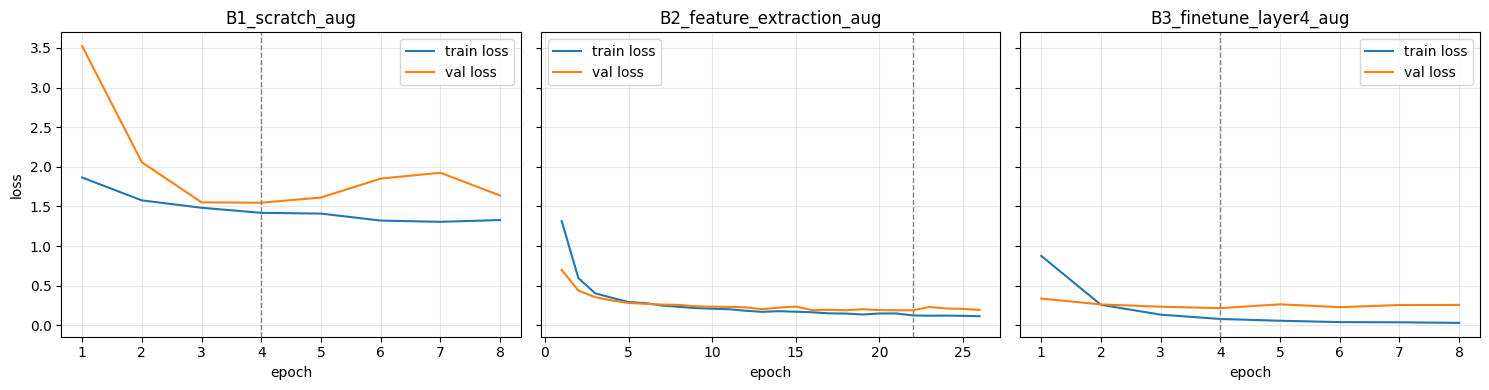

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, key in zip(axes, ["B1_scratch_aug", "B2_feature_extraction_aug", "B3_finetune_layer4_aug"]):
    h = pd.DataFrame(results[key]["history"])
    ax.plot(h["epoch"], h["train_loss"], label="train loss")
    ax.plot(h["epoch"], h["val_loss"], label="val loss")
    ax.axvline(results[key]["best_epoch"], ls="--", c="gray", lw=1)
    ax.set_title(key); ax.set_xlabel("epoch"); ax.grid(alpha=.3); ax.legend()
axes[0].set_ylabel("loss")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/curves_B1_B2_B3.png", dpi=200)
plt.show()

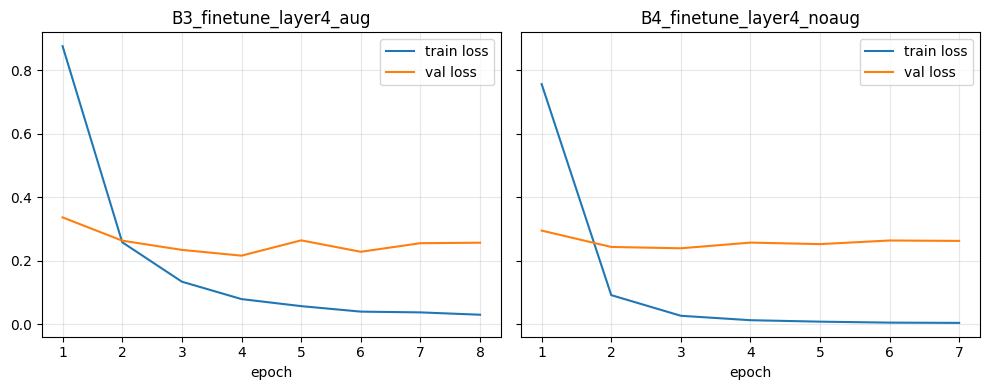

In [13]:
# Kurva buat augment
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, key in zip(axes, ["B3_finetune_layer4_aug", "B4_finetune_layer4_noaug"]):
    h = pd.DataFrame(results[key]["history"])
    ax.plot(h["epoch"], h["train_loss"], label="train loss")
    ax.plot(h["epoch"], h["val_loss"], label="val loss")
    ax.set_title(key); ax.set_xlabel("epoch"); ax.grid(alpha=.3); ax.legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/curves_B4_augmentation.png", dpi=200)
plt.show()

## 8. Failure analysis (C3)
Model terbaik = test Macro F1 tertinggi di antara B1-B4 (B5 dievaluasi terpisah karena arsitekturnya berbeda).

Model terbaik: B2_feature_extraction_aug 0.9334845642977212
Salah prediksi: 10 dari 150


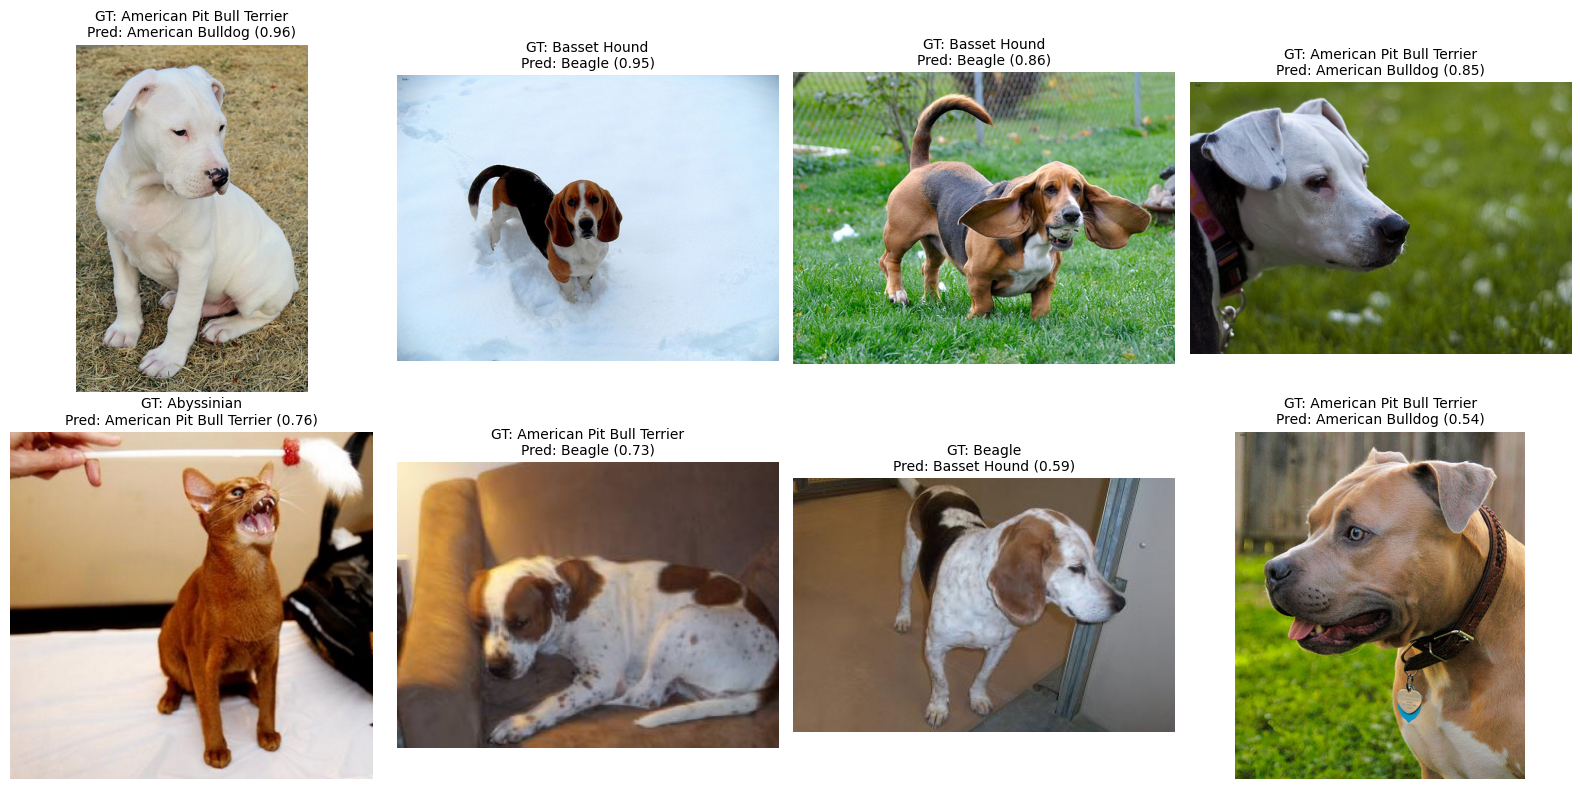

,file,ground_truth,prediction,confidence
0,data/oxford-iiit-pet/images/american_pit_bull_...,American Pit Bull Terrier,American Bulldog,0.956469
1,data/oxford-iiit-pet/images/basset_hound_68.jpg,Basset Hound,Beagle,0.954735
2,data/oxford-iiit-pet/images/basset_hound_75.jpg,Basset Hound,Beagle,0.857580
3,data/oxford-iiit-pet/images/american_pit_bull_...,American Pit Bull Terrier,American Bulldog,0.848253
4,data/oxford-iiit-pet/images/Abyssinian_20.jpg,Abyssinian,American Pit Bull Terrier,0.760958
5,data/oxford-iiit-pet/images/american_pit_bull_...,American Pit Bull Terrier,Beagle,0.734268
6,data/oxford-iiit-pet/images/beagle_135.jpg,Beagle,Basset Hound,0.588844
7,data/oxford-iiit-pet/images/american_pit_bull_...,American Pit Bull Terrier,American Bulldog,0.536336


In [11]:
main_keys = [k for k in results if not k.startswith("B5")]
best_key = max(main_keys, key=lambda k: results[k]["test_macro_f1"])
print("Model terbaik:", best_key, results[best_key]["test_macro_f1"])

mode = "scratch" if best_key.startswith("B1") else "feature_extraction" if best_key.startswith("B2") else "finetune_layer4"
best_model, _ = build_resnet18(mode)
best_model.load_state_dict(torch.load(results[best_key]["checkpoint"], map_location=DEVICE))
best_model = best_model.to(DEVICE)

_, _, test_loader = loaders_plain
y_true, y_pred, conf = predict(best_model, test_loader)
wrong = np.where(y_true != y_pred)[0]
print(f"Salah prediksi: {len(wrong)} dari {len(y_true)}")

show = wrong[np.argsort(-conf[wrong])][:8]
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
failure_rows = []
for ax, i in zip(axes.ravel(), show):
    ax.imshow(Image.open(test_p[i]).convert("RGB")); ax.axis("off")
    ax.set_title(f"GT: {class_names[y_true[i]]}\nPred: {class_names[y_pred[i]]} ({conf[i]:.2f})", fontsize=10)
    failure_rows.append({"file": test_p[i], "ground_truth": class_names[y_true[i]],
                         "prediction": class_names[y_pred[i]], "confidence": float(conf[i])})
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/failure_cases.png", dpi=200)
plt.show()
pd.DataFrame(failure_rows).to_csv(f"{OUT_DIR}/failure_cases.csv", index=False)
pd.DataFrame(failure_rows)